Ran LU - Paris Saclay M2 AI - ran.lu@universite-paris-saclay.fr

# Task 1 - FIR delay effect

This notebook applies the finite impulse response delay
\[
s[t] = e[t] + \alpha e[t-D]
\]
to the real recording `data/music.wav`. It implements the filter in the time domain and measures its impulse and frequency responses numerically.

## Setup and real audio input

,File,Sample rate (Hz),Samples,Duration (s),RMS,Peak magnitude
0,data/music.wav,16000,140001,8.7501,0.2293,0.9736


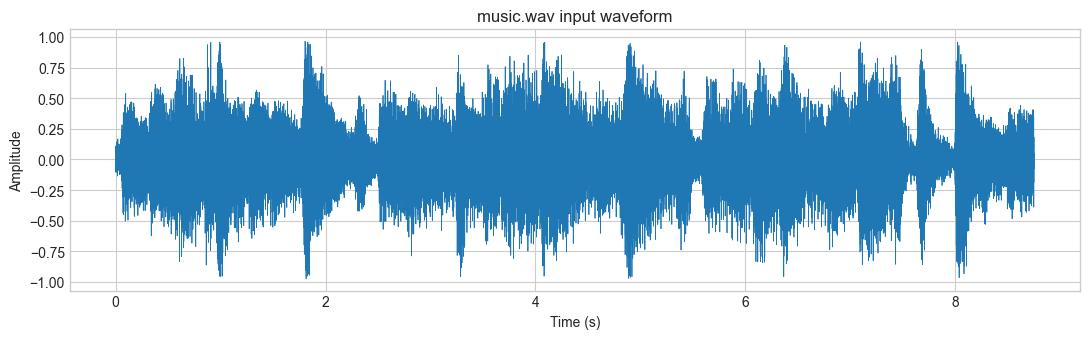

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, display
from scipy.io import wavfile

plt.style.use("seaborn-v0_8-whitegrid")

AUDIO_PATH = Path("data/music.wav")
sample_rate, samples = wavfile.read(AUDIO_PATH)
if samples.ndim == 2:
    samples = samples.mean(axis=1)
if np.issubdtype(samples.dtype, np.integer):
    scale = max(abs(np.iinfo(samples.dtype).min), np.iinfo(samples.dtype).max)
    audio = samples.astype(np.float64) / scale
else:
    audio = samples.astype(np.float64)
audio -= audio.mean()

time = np.arange(len(audio)) / sample_rate
alpha = 0.65
delay_seconds = 0.12
delay_samples = int(round(delay_seconds * sample_rate))

input_summary = pd.DataFrame({
    "File": [str(AUDIO_PATH)],
    "Sample rate (Hz)": [sample_rate],
    "Samples": [len(audio)],
    "Duration (s)": [len(audio) / sample_rate],
    "RMS": [np.sqrt(np.mean(audio**2))],
    "Peak magnitude": [np.max(np.abs(audio))],
})
display(input_summary.round(4))

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(time, audio, lw=0.55)
ax.set(title="music.wav input waveform", xlabel="Time (s)", ylabel="Amplitude")
fig.tight_layout()
plt.show()
display(Audio(audio, rate=sample_rate, normalize=False))

### Result analysis

`music.wav` is a mono 16-bit recording containing 140,001 samples at 16 kHz, for a duration of 8.7501 s. After normalization and DC removal, its RMS level is 0.2293 and its peak magnitude is 0.9736. The waveform contains sustained musical content rather than an isolated impulse, so the delayed copy will overlap the original for most of the recording.

### Code analysis

The loader reads the real WAV file with SciPy, supports either mono or multichannel arrays, and converts integer PCM samples to floating point. Removing the mean prevents a DC component from being copied by the delay. The sample-based delay is derived from 0.12 s and the file's measured sample rate, giving (D=1920) samples.

## 1. Time-domain FIR implementation

In [2]:
def fir_delay(input_signal, attenuation, delay):
    """Apply y[n] = x[n] + attenuation*x[n-delay]."""
    if delay < 0:
        raise ValueError("delay must be non-negative")
    output = np.zeros_like(input_signal, dtype=float)
    for n, sample in enumerate(input_signal):
        output[n] = sample
        if n >= delay:
            output[n] += attenuation * input_signal[n - delay]
    return output


fir_output = fir_delay(audio, alpha, delay_samples)


,Signal,RMS,Peak magnitude
0,Input,0.2293,0.9736
1,FIR output,0.2789,1.3148


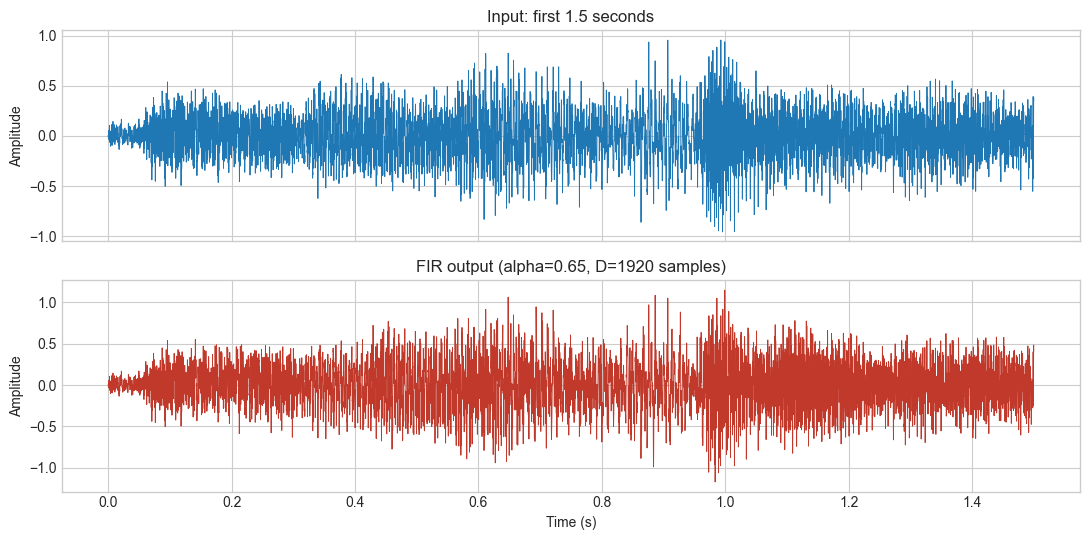

In [3]:
input_rms = np.sqrt(np.mean(audio**2))
output_rms = np.sqrt(np.mean(fir_output**2))
fir_metrics = pd.DataFrame({
    "Signal": ["Input", "FIR output"],
    "RMS": [input_rms, output_rms],
    "Peak magnitude": [np.max(np.abs(audio)), np.max(np.abs(fir_output))],
})
display(fir_metrics.round(4))

view_end = int(1.5 * sample_rate)
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].plot(time[:view_end], audio[:view_end], lw=0.65)
axes[0].set(title="Input: first 1.5 seconds", ylabel="Amplitude")
axes[1].plot(time[:view_end], fir_output[:view_end], lw=0.65, color="#c0392b")
axes[1].set(
    title=f"FIR output (alpha={alpha}, D={delay_samples} samples)",
    xlabel="Time (s)",
    ylabel="Amplitude",
)
fig.tight_layout()
plt.show()
display(Audio(fir_output, rate=sample_rate, normalize=True))

### Result analysis

For the real music signal, the direct and delayed paths overlap continuously after 0.12 s. The RMS rises from 0.2293 to 0.2789, a gain of 1.70 dB, while the peak magnitude reaches 1.3148. This peak exceeds the normalized PCM range, so the playback widget normalizes the result; exporting directly to 16-bit PCM without scaling would clip. Perceptually, the output combines one echo with comb-filter coloration caused by interference between the two paths.

### Code analysis

The implementation reads the delayed term only from `input_signal`, so it has no feedback and creates exactly one delayed copy. The metrics are calculated before playback normalization, preserving the true filter output levels. The displayed 1.5-second interval is long enough to contain several musical events while keeping the 0.12-second displacement visible.

## 2. Numerical impulse response

Non-zero impulse-response samples: [0, 1920]
Values: [1.0, 0.65]


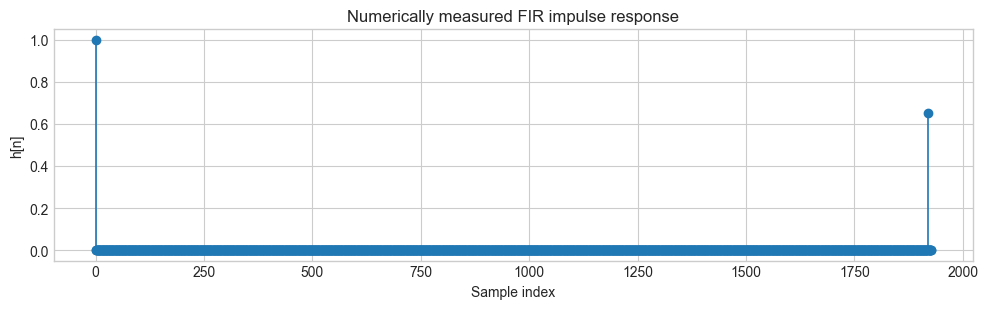

In [4]:
impulse_length = delay_samples + 8
unit_impulse = np.zeros(impulse_length)
unit_impulse[0] = 1.0
impulse_response = fir_delay(unit_impulse, alpha, delay_samples)
nonzero_indices = np.flatnonzero(np.abs(impulse_response) > 1e-12)
print("Non-zero impulse-response samples:", nonzero_indices.tolist())
print("Values:", impulse_response[nonzero_indices].tolist())

fig, ax = plt.subplots(figsize=(10, 3.2))
markerline, stemlines, baseline = ax.stem(np.arange(impulse_length), impulse_response, basefmt=" ")
plt.setp(stemlines, linewidth=1.2)
ax.set(title="Numerically measured FIR impulse response", xlabel="Sample index", ylabel="h[n]")
fig.tight_layout()
plt.show()


### Result analysis

The measured response has non-zero samples only at (n=0) and (n=1920), with amplitudes 1 and 0.65. This is exactly (h[n]=\delta[n]+0.65\delta[n-1920]), confirming a finite impulse response with one echo.

### Code analysis

The numerical measurement sends a unit impulse through the same function used for `music.wav`. Detecting the non-zero indices from the returned array verifies the implementation independently of the theoretical formula; the extra eight samples ensure that the delayed coefficient is not the final array element.

## 3. Numerical frequency response

,Minimum magnitude (dB),Maximum magnitude (dB),Ripple spacing (Hz)
0,-9.1186,4.3497,8.3333


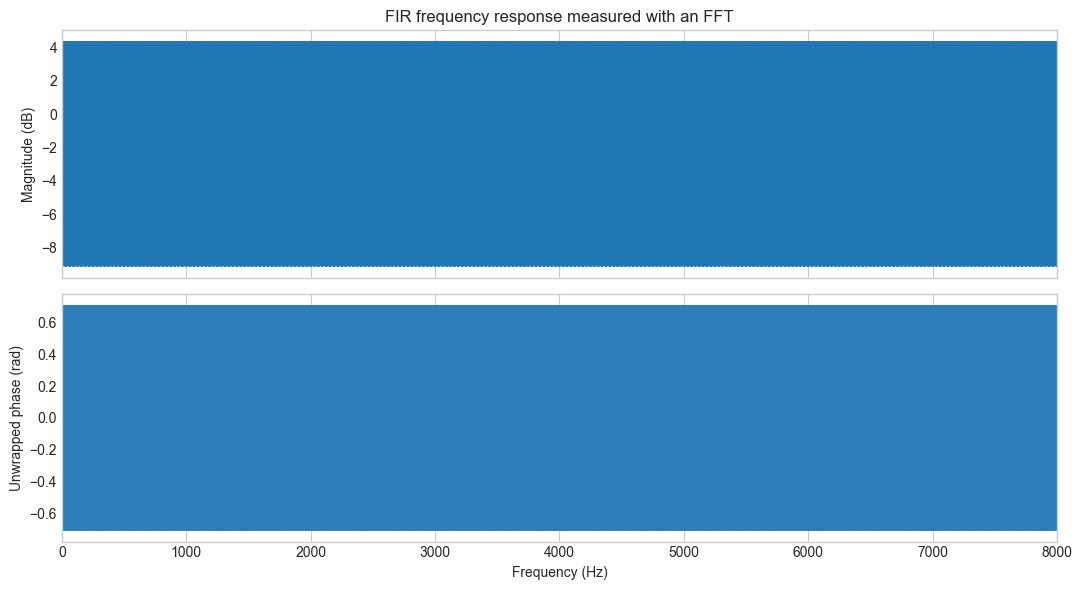

In [5]:
fft_size = 2**17
frequencies = np.fft.rfftfreq(fft_size, 1 / sample_rate)
frequency_response = np.fft.rfft(impulse_response, n=fft_size)
magnitude = np.abs(frequency_response)
magnitude_db = 20 * np.log10(np.maximum(magnitude, 1e-12))
phase = np.unwrap(np.angle(frequency_response))

response_summary = pd.DataFrame({
    "Minimum magnitude (dB)": [magnitude_db.min()],
    "Maximum magnitude (dB)": [magnitude_db.max()],
    "Ripple spacing (Hz)": [sample_rate / delay_samples],
})
display(response_summary.round(4))

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(frequencies, magnitude_db, lw=0.8)
axes[0].set(title="FIR frequency response measured with an FFT", ylabel="Magnitude (dB)")
axes[0].set_xlim(0, sample_rate / 2)
axes[1].plot(frequencies, phase, lw=0.8, color="#2c7fb8")
axes[1].set(xlabel="Frequency (Hz)", ylabel="Unwrapped phase (rad)")
fig.tight_layout()
plt.show()

### Result analysis

The numerical response ranges from -9.1186 dB to 4.3497 dB, corresponding to the theoretical magnitudes (1-\alpha=0.35) and (1+\alpha=1.65). Its comb ripples repeat every (f_s/D=8.3333) Hz. Consequently, the broadband music input is alternately attenuated and reinforced across frequency, explaining the coloration in addition to the audible echo.

### Code analysis

The FFT is applied to the measured impulse response rather than evaluating the closed-form expression. Zero-padding to 131,072 points provides a 0.1221 Hz frequency grid, which resolves the 8.3333 Hz ripple spacing. `rfft` retains the non-negative frequencies, and the magnitude floor only prevents taking `log10(0)`.

### Conclusion

The real recording confirms both effects of this FIR structure: one time-domain echo and a periodic comb response. The filter is always BIBO-stable because the absolute sum of its two impulse-response coefficients is finite.